# Deo et al. 2024 — exploring the Study (`Deo2024Bimanual`)

`Deo2024Bimanual` turns the raw daily `.mat` files into standardized neuralset events. **One
timeline is one block** (204 across the 13 days): a contiguous, single-`loop_type` recording,
sliced out of each day by `blockNum`. Each timeline emits one whole-block `SpikeCounts` neural
stream, the two cursors' and targets' positions as per-hand `CursorPositionSeries` /
`TargetPositionSeries`, and one `Stimulus` (movement cue) + `Action` (attempted movement) per
trial. `loop_type` / `session` / `block` ride on the timeline; select neural vs behavior by
**type**, slice conditions by **attribute**.

> **Data path.** Source data lives on an external drive; this notebook reads its location from `NEURALSHED_DATA_ROOT`, loaded from a **gitignored `./.env`** at the repo root (via `load_dotenv`). Set it once there: `NEURALSHED_DATA_ROOT=/path/to/source/data`.


In [1]:
import warnings; warnings.filterwarnings("ignore")
from dotenv import load_dotenv, find_dotenv
load_dotenv(find_dotenv(usecwd=True))          # NEURALSHED_DATA_ROOT from the repo-root ./.env
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

import neuralshed.events, neuralshed.extractors        # register custom types
from neuralshed.datasets.deo_2024 import study
from neuralshed.datasets.utils import dataset_dir
from neuralset.events import etypes
from neuralset.events.study import STUDIES
from neuralshed.extractors import NeuralFeatureExtractor, BehavioralSeriesExtractor

print("Deo2024Bimanual registered:", "Deo2024Bimanual" in STUDIES)
root = dataset_dir("deo_2024") / "data"
s = study.Deo2024Bimanual(path=root)
print("data:", s.path, "| exists:", s.path.exists())


Deo2024Bimanual registered: True
data: /media/heberto/Expansion/tether/datasets/deo_2024/data | exists: True


## 1. Timelines (one per block)

One row per block, carrying `loop_type` and the block's identity. `iter_timelines` slices each
day's `.mat` by `blockNum` (204 timelines: open-loop, closed-loop, and closed-loop-recal).

In [2]:
timelines = list(s.iter_timelines())
tldf = pd.DataFrame(timelines)
print("n timelines:", len(timelines), "| subject:", tldf.subject.unique().tolist())
display(tldf.groupby("loop_type").size().rename("n_blocks").reset_index())
display(tldf[["subject", "session", "block", "loop_type", "date"]].head())

n timelines: 204 | subject: ['T5']


,loop_type,n_blocks
0,closed_loop,92
1,closed_loop_recal,20
2,open_loop,92


,subject,session,block,loop_type,date
0,T5,t5_06_02_2021,12,open_loop,2021-06-02
1,T5,t5_06_02_2021,13,open_loop,2021-06-02
2,T5,t5_06_02_2021,14,open_loop,2021-06-02
3,T5,t5_06_02_2021,15,open_loop,2021-06-02
4,T5,t5_06_02_2021,16,open_loop,2021-06-02


## 2. Raw events for one block

`_load_timeline_events` emits the whole-block streams (via `SpecialLoader`) plus one `Stimulus`
and one `Action` per trial. The five continuous rows span the block; the markers are per trial.

In [3]:
tl = next(t for t in timelines if t["loop_type"] == "open_loop")
raw = s._load_timeline_events(tl)
print("timeline:", tl["session"], "block", tl["block"], "| rows:", len(raw),
      "| types:", raw["type"].value_counts().to_dict())
cols = ["type", "feature", "start", "duration", "code", "description", "effector"]
display(raw[[c for c in cols if c in raw.columns]].head(8))

timeline: t5_06_02_2021 block 12 | rows: 161 | types: {'Stimulus': 78, 'Action': 78, 'CursorPositionSeries': 2, 'TargetPositionSeries': 2, 'SpikeCounts': 1}


,type,feature,start,duration,code,description,effector
0,SpikeCounts,threshold_crossings,0.00,290.24,NaN,NaN,NaN
1,CursorPositionSeries,right_cursor_position,0.00,290.24,NaN,NaN,right
2,CursorPositionSeries,left_cursor_position,0.00,290.24,NaN,NaN,left
3,TargetPositionSeries,right_target_position,0.00,290.24,NaN,NaN,right
4,TargetPositionSeries,left_target_position,0.00,290.24,NaN,NaN,left
5,Stimulus,NaN,0.04,2.70,3.0,Bi,NaN
6,Action,NaN,1.50,1.24,3.0,attempted bimanual movement,NaN
7,Stimulus,NaN,3.30,3.56,2.0,UniL,NaN


## 3. Standardized events (`.run()`)

The framework injects `subject`/`timeline`/`study` and broadcasts the timeline attributes
(`loop_type`, `session`, `block`, `date`) onto every row.

In [5]:
idx = next(i for i, t in enumerate(timelines) if t is tl)
events = study.Deo2024Bimanual(path=root, query=f"timeline_index == {idx}").run()
carried = [c for c in ["subject", "loop_type", "session", "block", "date"] if c in events.columns]
print("events:", events.shape, "| types:", events.type.value_counts().to_dict())
print("subject:", events.subject.iloc[0], "| carried:", carried)
display(events[[c for c in ["type", "feature", "start", "duration", "loop_type", "description"]
                if c in events.columns]].head())

events: (161, 32) | types: {'Stimulus': 78, 'Action': 78, 'CursorPositionSeries': 2, 'TargetPositionSeries': 2, 'SpikeCounts': 1}
subject: Deo2024Bimanual/T5 | carried: ['subject', 'loop_type', 'session', 'block', 'date']


,type,feature,start,duration,loop_type,description
0,SpikeCounts,threshold_crossings,0.0,290.24,open_loop,NaN
1,CursorPositionSeries,right_cursor_position,0.0,290.24,open_loop,NaN
2,CursorPositionSeries,left_cursor_position,0.0,290.24,open_loop,NaN
3,TargetPositionSeries,right_target_position,0.0,290.24,open_loop,NaN
4,TargetPositionSeries,left_target_position,0.0,290.24,open_loop,NaN


## 4. Read the neural stream through the extractor

`NeuralFeatureExtractor` windows the whole-block `SpikeCounts` event to `(192, T)` at a chosen
rate. Here, one bimanual trial's window.

neural for one Bi trial: (192, 135)


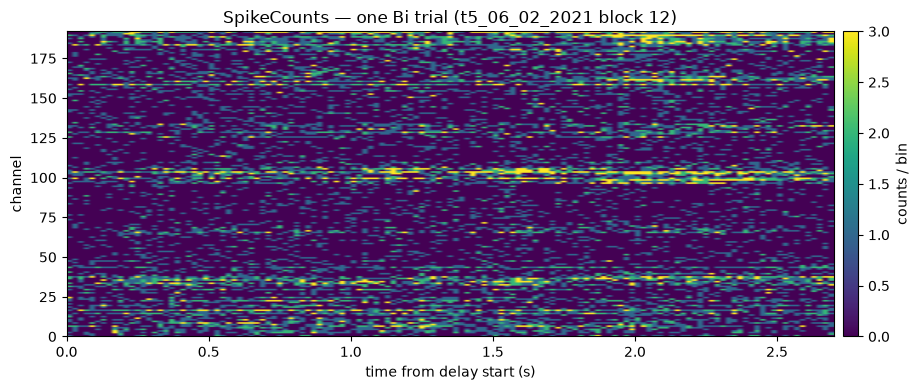

In [6]:
neural = etypes.Event.from_dict(events[events.type == "SpikeCounts"].iloc[0].to_dict())
bi = events[(events.type == "Stimulus") & (events.description == "Bi")]
bi = bi.iloc[0] if len(bi) else events[events.type == "Stimulus"].iloc[0]

nx = NeuralFeatureExtractor(target_unit="native", event_types=("SpikeCounts",), frequency=50.0)
seg = nx([neural], start=float(bi.start), duration=float(bi.duration)).numpy()
print("neural for one", bi.description, "trial:", seg.shape)

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(seg, aspect="auto", origin="lower", cmap="viridis",
               vmin=0, vmax=np.percentile(seg, 98), extent=[0, float(bi.duration), 0, 192])
ax.set_xlabel("time from delay start (s)"); ax.set_ylabel("channel")
ax.set_title(f"SpikeCounts — one {bi.description} trial ({tl['session']} block {tl['block']})")
fig.colorbar(im, ax=ax, pad=0.01, label="counts / bin")
plt.tight_layout(); plt.show()

## 5. Read cursor & target through the extractor

The two hands are separate `CursorPositionSeries` (select by `effector`). Both cursors and their
targets, read through `BehavioralSeriesExtractor`, for the same trial: each cursor travels to its
cued target.

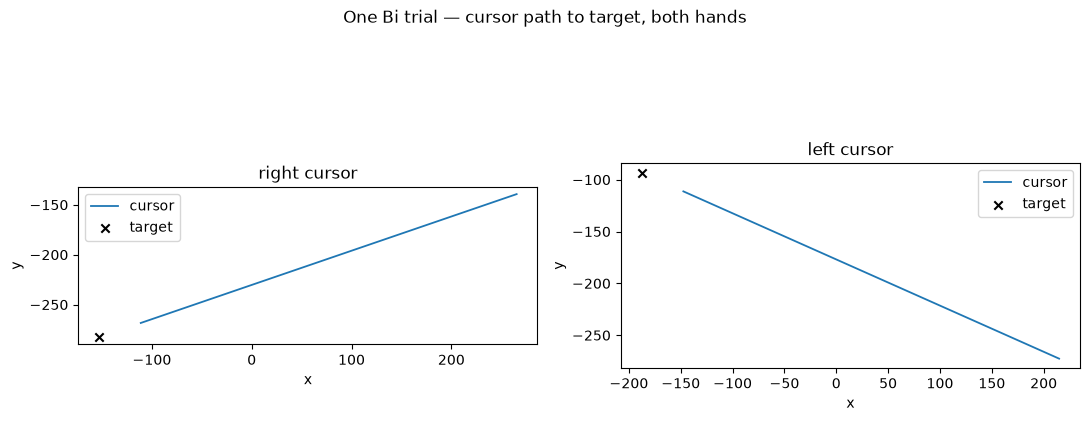

In [7]:
pos = {r.feature: etypes.Event.from_dict(r.to_dict())
       for _, r in events[events.type.isin(["CursorPositionSeries", "TargetPositionSeries"])].iterrows()}

def read(feature, etype, tr):                       # window a per-hand stream to a trial
    ex = BehavioralSeriesExtractor(event_types=(etype,), frequency=50.0)
    return ex([pos[feature]], start=float(tr.start), duration=float(tr.duration)).numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, hand in zip(axes, ["right", "left"]):
    c = read(f"{hand}_cursor_position", "CursorPositionSeries", bi)
    t = read(f"{hand}_target_position", "TargetPositionSeries", bi)
    ax.plot(c[0], c[1], lw=1.3, label="cursor")
    ax.scatter(t[0, -1], t[1, -1], c="k", marker="x", zorder=3, label="target")
    ax.set_title(f"{hand} cursor"); ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.set_aspect("equal"); ax.legend()
fig.suptitle(f"One {bi.description} trial — cursor path to target, both hands")
plt.tight_layout(); plt.show()

## Summary

- **One timeline per block** (204): `SpikeCounts` (192 ch, 50 Hz) + per-hand `CursorPositionSeries`
  / `TargetPositionSeries`, plus `Stimulus` / `Action` per trial.
- Whole-block streams load lazily via `SpecialLoader`; `NeuralFeatureExtractor` /
  `BehavioralSeriesExtractor` window them to `(features, T)` tensors on a chosen clock.
- Filter by **type** (neural vs cursor vs target) and slice by **attribute** (`loop_type`,
  `effector`, movement type via `code` / `description`).
- Reused package Events and Extractors, no deo-specific types.

Next: `03_model_example.ipynb` decodes cursor kinematics from the neural features.